# Linear regression in diabetes dataset

Let's explore the datasets that are included in this Python library. These datasets have been cleaned and formatted for use in ML algorithms.

First, we will load the diabetes dataset. Do this in the cell below by importing the datasets and then loading the dataset  to the `diabetes` variable using the `load_diabetes()` function ([documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)).

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import pandas as pd
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()

In [4]:
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

Let's explore this variable by looking at the different attributes (keys) of `diabetes`. Note that the `load_diabetes` function does not return dataframes. It returns you a Python dictionary.

In [4]:
diabetes.keys()

dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])

#### The next step is to read the description of the dataset. 

Print the description in the cell below using the `DESCR` attribute of the `diabetes` variable. Read the data description carefully to fully understand what each column represents.

*Hint: If your output is ill-formatted by displaying linebreaks as `\n`, it means you are not using the `print` function.*

In [6]:
print(diabetes['DESCR'])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

#### Based on the data description, answer the following questions:

1. How many attributes are there in the data? What do they mean?

1. What is the relation between `diabetes['data']` and `diabetes['target']`?

1. How many records are there in the data?

In [ ]:
#:Number of Attributes: First 10 columns are numeric predictive values
''':Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low- lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level'''

':Attribute Information:\n    - age     age in years\n    - sex\n    - bmi     body mass index\n    - bp      average blood pressure\n    - s1      tc, total serum cholesterol\n    - s2      ldl, low-density lipoproteins\n    - s3      hdl, high-density lipoproteins\n    - s4      tch, total cholesterol / HDL\n    - s5      ltg, possibly log of serum triglycerides level\n    - s6      glu, blood sugar level'

2. diabetes['data'] contiene las variables predictivas para cada paciente, mientras que diabetes['target'] contiene la respuesta de interés, que es una medida cuantitativa de la progresión de la enfermedad un año después del punto de partida.

3. 442


#### Now explore what are contained in the *data* portion as well as the *target* portion of `diabetes`. 

Scikit-learn typically takes in 2D numpy arrays as input (though pandas dataframes are also accepted). Inspect the shape of `data` and `target`. Confirm they are consistent with the data description.

In [14]:

print("Forma de 'data':", diabetes['data'].shape)
print("Forma de 'target':", diabetes['target'].shape)

Forma de 'data': (442, 10)
Forma de 'target': (442,)


## Building a regression model

The data have already been split to predictor (*data*) and response (*target*) variables. Given this information, we'll apply what we have previously learned about linear regression and apply the algorithm to the diabetes dataset.

#### In the cell below, import the `linear_model` class from `sklearn`. 

In [15]:
from sklearn.linear_model import LinearRegression

#### Create a new instance of the linear regression model and assign the new instance to the variable `diabetes_model`.

In [16]:
diabetes_model = LinearRegression()

#### Next, let's split the training and test data.

Define `diabetes_data_train`, `diabetes_target_train`, `diabetes_data_test`, and `diabetes_target_test`. Use the last 20 records for the test data and the rest for the training data.

In [17]:
# todo menos los últimos 20 registros para entrenar
diabetes_data_train = diabetes['data'][:-20]
diabetes_target_train = diabetes['target'][:-20]

# solo los últimos 20 registros para pruebas
diabetes_data_test = diabetes['data'][-20:]
diabetes_target_test = diabetes['target'][-20:]

Perform a brief exploratory analysis to investigate the conditions necessary for linear regression. This analysis will help you understand the distribution of the target variable and its correlations with other features.

Fit the training data and target to `diabetes_model`. Print the *intercept* and *coefficients* of the model.

In [20]:
# Convertimos a DataFrame para facilitar el análisis exploratorio
df_diabetes = pd.DataFrame(diabetes['data'], columns=diabetes['feature_names'])
df_diabetes['target'] = diabetes['target']
df_diabetes


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


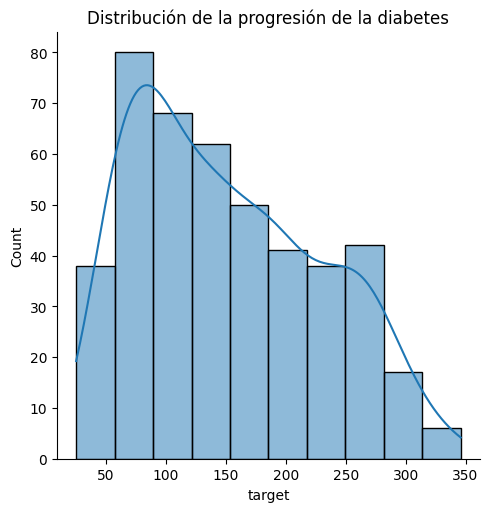

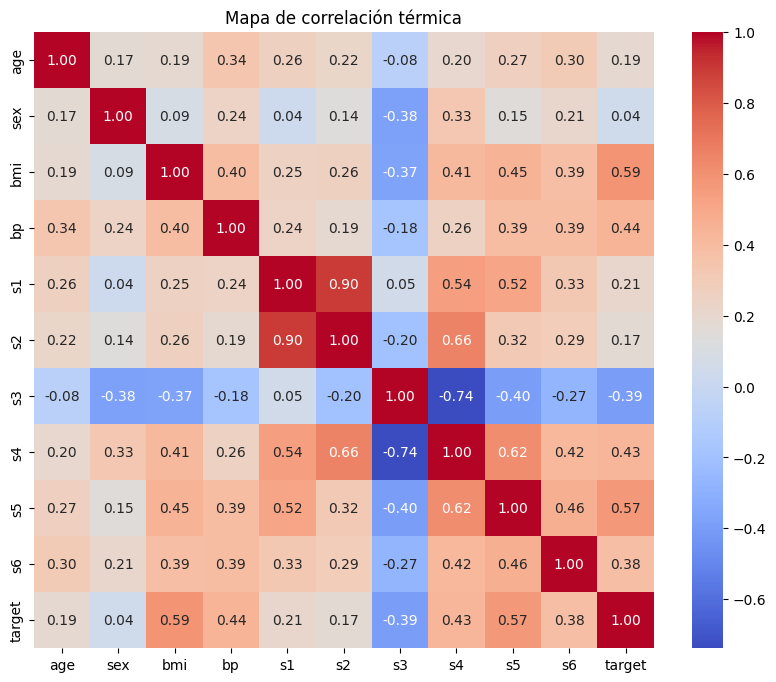

In [21]:


# 1. Distribución de la variable objetivo (target)
sns.displot(df_diabetes['target'], kde=True)
plt.title('Distribución de la progresión de la diabetes')
plt.show()

# 2. Correlación entre las variables
plt.figure(figsize=(10, 8))
sns.heatmap(df_diabetes.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title('Mapa de correlación térmica')
plt.show()

In [22]:
diabetes_model.fit(diabetes_data_train, diabetes_target_train)

print("Intersección (Intercept):", diabetes_model.intercept_)
print("Coeficientes (Coefficients):\\n", diabetes_model.coef_)

Intersección (Intercept): 152.76429169049118
Coeficientes (Coefficients):\n [ 3.06094248e-01 -2.37635570e+02  5.10538048e+02  3.27729878e+02
 -8.14111926e+02  4.92799595e+02  1.02841240e+02  1.84603496e+02
  7.43509388e+02  7.60966464e+01]


#### Inspecting the results

From the outputs you should have seen:

- The intercept is a float number.
- The coefficients are an array containing 10 float numbers.

This is the linear regression model fitted to your training dataset.

#### Using your fitted linear regression model, predict the *y* of `diabetes_data_test`.

In [23]:
predictions = diabetes_model.predict(diabetes_data_test)

#### Print your `diabetes_target_test` and compare with the prediction. 

In [24]:
# Creamos un DataFrame para comparar fácilmente el valor real y el predicho
comparacion = pd.DataFrame({'Valor Real': diabetes_target_test, 'Predicción': predictions})
print(comparacion)

    Valor Real  Predicción
0        233.0  197.618985
1         91.0  155.440320
2        111.0  172.888751
3        152.0  111.532706
4        120.0  164.793973
5         67.0  131.067659
6        310.0  259.124412
7         94.0  100.478737
8        183.0  117.060054
9         66.0  124.302616
10       173.0  218.368681
11        72.0   61.195819
12        49.0  132.248379
13        64.0  120.332935
14        48.0   52.545130
15       178.0  194.037468
16       104.0  102.575643
17       132.0  123.567787
18       220.0  211.034653
19        57.0   52.602217


#### Is `diabetes_target_test` exactly the same as the model prediction? Use different error metrics

In [25]:
from sklearn import metrics
import numpy as np

print('MAE:', metrics.mean_absolute_error(diabetes_target_test, predictions))
print('MSE:', metrics.mean_squared_error(diabetes_target_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(diabetes_target_test, predictions)))

MAE: 36.60961865545878
MSE: 2004.5186863342078
RMSE: 44.771851495489976


#### Iterate with a new model to assess if any improvements can be made compared to the previous one. Consider reducing the number of variables or using `StandardScaler` to enhance model performance.

In [26]:
from sklearn.preprocessing import StandardScaler

# Seleccionamos solo las variables con mayor correlación con el 'target' (basado en el EDA)
features_importantes = ['bmi', 's5', 'bp', 's4']
X = df_diabetes[features_importantes]
y = df_diabetes['target']

# Separamos nuevamente dejando 20 para test
X_train, X_test = X[:-20], X[-20:]
y_train, y_test = y[:-20], y[-20:]

# Aunque ya vienen escalados, pasamos el StandardScaler como pide el ejercicio
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Entrenamos el nuevo modelo
nuevo_modelo = LinearRegression()
nuevo_modelo.fit(X_train_scaled, y_train)
nuevas_predicciones = nuevo_modelo.predict(X_test_scaled)

# Comprobamos si las métricas mejoran
print('--- Nuevo Modelo con variables reducidas y StandardScaler ---')
print('MAE:', metrics.mean_absolute_error(y_test, nuevas_predicciones))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, nuevas_predicciones)))

--- Nuevo Modelo con variables reducidas y StandardScaler ---
MAE: 38.68109954288582
RMSE: 45.917394340365306
